# 🗑️ Klasifikasi Sampah dengan ShuffleNetV2 (PyTorch) + KaggleHub

Notebook ini mengadaptasi alur kerja dari `train_245_class.py`, menggunakan **ShuffleNetV2** sebagai backbone (bukan SqueezeNet, sesuai kode sumber yang dilampirkan), dan mengunduh dataset secara otomatis via **KaggleHub**.

**Dataset:** [Recyclable and Household Waste Classification](https://www.kaggle.com/datasets/alistairking/recyclable-and-household-waste-classification) — 15.000 gambar, 30 kelas, 256×256 px.

**Model:** ShuffleNetV2 (pretrained ImageNet) — sangat ringan, cocok untuk CPU/GPU.

## 1. Setup & Instalasi

In [1]:
%pip install kagglehub torch torchvision pillow tqdm scikit-learn matplotlib seaborn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import shutil
import random
import copy
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix

ImageFile.LOAD_TRUNCATED_IMAGES = True
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print('Device:', device)
print('PyTorch:', torch.__version__)

Device: cuda:0
PyTorch: 2.15.0+cu132


## 2. Download Dataset via KaggleHub

Dataset ini memiliki struktur bertingkat: `images/<kategori_item>/default/*.png` dan `images/<kategori_item>/real_world/*.png`. Kita perlu **flatten** ke format `flat/<nama_kelas>/gambar.png` agar bisa dibaca `ImageFolder` [citation:1][citation:16].

In [3]:
import os
from pathlib import Path
import kagglehub

dataset_path = kagglehub.dataset_download(
    "alistairking/recyclable-and-household-waste-classification"
)
print('Dataset path:', dataset_path)

# KaggleHub pada beberapa versi menyimpan dataset di images/images/<kelas>/...
def class_dirs_with_splits(root):
    root = Path(root)
    if not root.is_dir():
        return []
    return [
        p for p in root.iterdir()
        if p.is_dir()
        and any((p / split).is_dir() for split in ('default', 'real_world'))
    ]

candidates = []
for root, dirs, files in os.walk(dataset_path):
    if os.path.basename(root).lower() == 'images':
        class_dirs = class_dirs_with_splits(root)
        if class_dirs:
            candidates.append((len(class_dirs), root, class_dirs))

if not candidates:
    raise FileNotFoundError(
        f"Tidak menemukan folder kelas berisi 'default'/'real_world' "
        f"di dataset: {dataset_path}. "
        "Periksa struktur folder dataset yang diunduh."
    )

_, IMAGES_ROOT, class_dirs = max(candidates, key=lambda item: item[0])
categories = sorted(p.name for p in class_dirs)
print('IMAGES_ROOT:', IMAGES_ROOT)
print(f'Jumlah kategori item: {len(categories)}')

Dataset path: /mnt/home/probation-03/.cache/kagglehub/datasets/alistairking/recyclable-and-household-waste-classification/versions/1
IMAGES_ROOT: /mnt/home/probation-03/.cache/kagglehub/datasets/alistairking/recyclable-and-household-waste-classification/versions/1/images/images
Jumlah kategori item: 30


## 3. Flatten + Split Dataset (80/10/10)

Karena dataset asli tidak menyediakan split train/val/test, kita split manual per kelas dengan rasio 80/10/10 [citation:1].

In [4]:
import shutil
from pathlib import Path
from tqdm import tqdm

WORK_DIR = Path('./waste_shufflenet_data')
FLAT_DIR = WORK_DIR / 'flat_all'
SPLIT_DIR = WORK_DIR / 'split'
WORK_DIR.mkdir(parents=True, exist_ok=True)

# Bangun ulang folder hasil agar sisa struktur sebelumnya tidak ikut terbaca.
if FLAT_DIR.exists():
    shutil.rmtree(FLAT_DIR)
FLAT_DIR.mkdir(parents=True, exist_ok=True)

print('Flattening...')
for cat in tqdm(categories):
    cat_dir = Path(IMAGES_ROOT) / cat
    out_dir = FLAT_DIR / cat
    out_dir.mkdir(parents=True, exist_ok=True)

    for split_name in ('default', 'real_world'):
        sub = cat_dir / split_name
        if not sub.is_dir():
            continue

        for img_file in sub.rglob('*'):
            if img_file.is_file() and img_file.suffix.lower() in (
                '.png', '.jpg', '.jpeg', '.bmp', '.webp'
            ):
                dst = out_dir / f'{split_name}_{img_file.name}'
                shutil.copy2(img_file, dst)

empty_categories = [
    cat for cat in categories if not any((FLAT_DIR / cat).iterdir())
]
if empty_categories:
    raise ValueError(
        f'Tidak ada gambar yang berhasil disalin untuk kelas: {empty_categories}'
    )

print('Selesai flatten. Total kelas:', len(categories))

Flattening...


100%|██████████| 30/30 [02:26<00:00,  4.87s/it]

Selesai flatten. Total kelas: 30


In [5]:
import random
import shutil
from pathlib import Path

def data_set_split(
    src_data_folder,
    target_data_folder,
    train_scale=0.8,
    val_scale=0.1,
    test_scale=0.1
):
    if not abs(train_scale + val_scale + test_scale - 1.0) < 1e-9:
        raise ValueError('train_scale + val_scale + test_scale harus sama dengan 1.')

    src_root = Path(src_data_folder)
    target_root = Path(target_data_folder)

    # Hapus split lama agar data dari proses sebelumnya tidak tertinggal.
    if target_root.exists():
        shutil.rmtree(target_root)

    for split_name in ('train', 'val', 'test'):
        (target_root / split_name).mkdir(parents=True, exist_ok=True)

    class_names = sorted(
        p.name for p in src_root.iterdir() if p.is_dir()
    )
    random.seed(42)

    for class_name in class_names:
        files = [
            p for p in (src_root / class_name).iterdir()
            if p.is_file()
        ]
        random.shuffle(files)

        n = len(files)
        if n == 0:
            raise ValueError(f'Kelas {class_name!r} tidak memiliki gambar.')

        train_stop = int(n * train_scale)
        val_stop = int(n * (train_scale + val_scale))

        for i, src in enumerate(files):
            split_name = (
                'train' if i < train_stop
                else ('val' if i < val_stop else 'test')
            )
            dst_dir = target_root / split_name / class_name
            dst_dir.mkdir(parents=True, exist_ok=True)
            shutil.copy2(src, dst_dir / src.name)

print('Membuat ulang split dataset...')
data_set_split(FLAT_DIR, SPLIT_DIR)
print('Selesai split.')

Membuat ulang split dataset...


Selesai split.


In [6]:
for phase in ['train', 'val', 'test']:
    n = sum(len(fs) for _, _, fs in os.walk(SPLIT_DIR / phase))
    print(f'{phase:5s}: {n} images')

train: 12000 images
val  : 1500 images
test : 1500 images


## 4. DataLoader

In [7]:
def data_load(data_dir=str(SPLIT_DIR), batch_size=32):
    data_transforms = {
        'train': transforms.Compose([
            transforms.RandomResizedCrop(224),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ]),
        'val': transforms.Compose([
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ]),
    }
    data_transforms['test'] = data_transforms['val']

    image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
                      for x in ['train', 'val', 'test']}
    dataloaders = {x: DataLoader(image_datasets[x], batch_size=batch_size,
                                  shuffle=(x=='train'), num_workers=2, pin_memory=True)
                   for x in ['train', 'val', 'test']}
    dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val', 'test']}
    class_names = image_datasets['train'].classes
    return dataloaders, dataset_sizes, class_names

dataloaders, dataset_sizes, class_names = data_load(batch_size=32)
print('Jumlah kelas:', len(class_names))
print('Train:', dataset_sizes['train'], '| Val:', dataset_sizes['val'], '| Test:', dataset_sizes['test'])

Jumlah kelas: 30
Train: 12000 | Val: 1500 | Test: 1500


## 5. Bangun Model ShuffleNetV2

Kita pakai `models.shufflenet_v2_x1_0(weights=ShuffleNet_V2_X1_0_Weights.IMAGENET1K_V1)`. Layer akhirnya adalah `fc` (Linear). Kita ganti `model.fc` agar output = jumlah kelas dataset [citation:18].

In [8]:
def build_shufflenet(num_classes: int, pretrained: bool = True) -> nn.Module:
    weights = models.ShuffleNet_V2_X1_0_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.shufflenet_v2_x1_0(weights=weights)
    # Ganti layer fc (Linear) agar sesuai jumlah kelas
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model

model = build_shufflenet(num_classes=len(class_names), pretrained=True).to(device)
print(model.fc)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable params: {n_params:,}')

Downloading: "https://download.pytorch.org/models/shufflenetv2_x1-5666bf0f80.pth" to /mnt/home/probation-03/.cache/torch/hub/checkpoints/shufflenetv2_x1-5666bf0f80.pth


100%|██████████| 8.79M/8.79M [00:00<00:00, 43.1MB/s]


Linear(in_features=1024, out_features=30, bias=True)
Trainable params: 1,284,354


## 6. Training Loop (20 Epoch)

Sama seperti kode asli, kita simpan bobot terbaik berdasarkan akurasi validasi.

In [9]:
def train_model(model, dataloaders, dataset_sizes, criterion, optimizer, scheduler, num_epochs=20):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        for phase in ['train', 'val']:
            if phase == 'train': model.train()
            else: model.eval()

            running_loss = 0.0
            running_corrects = 0

            with tqdm(total=dataset_sizes[phase], desc=phase) as pbar:
                for inputs, labels in dataloaders[phase]:
                    inputs = inputs.to(device, non_blocking=True)
                    labels = labels.to(device, non_blocking=True)
                    optimizer.zero_grad()
                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()
                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels.data)
                    pbar.update(inputs.size(0))

            if phase == 'train': scheduler.step()
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = (running_corrects.double() / dataset_sizes[phase]).item()
            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc)
            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())
        print()

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:.4f}')
    model.load_state_dict(best_model_wts)
    return model, history

In [10]:
NUM_EPOCHS = 20
MODEL_PATH = 'shufflenetv2_waste.pth'

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

model, history = train_model(model, dataloaders, dataset_sizes, criterion, optimizer, scheduler, num_epochs=NUM_EPOCHS)
torch.save(model, MODEL_PATH)
print('Model disimpan ke', MODEL_PATH)

Epoch 1/20


train: 100%|██████████| 12000/12000 [00:42<00:00, 281.45it/s]


train Loss: 3.3976 Acc: 0.0460


val: 100%|██████████| 1500/1500 [00:01<00:00, 935.93it/s] 


val Loss: 3.3921 Acc: 0.0753

Epoch 2/20


train: 100%|██████████| 12000/12000 [00:14<00:00, 818.16it/s]


... (71 outputs left out)

train: 100%|██████████| 12000/12000 [00:15<00:00, 795.43it/s]


train Loss: 3.2411 Acc: 0.3548


val: 100%|██████████| 1500/1500 [00:01<00:00, 850.80it/s]

val Loss: 3.2331 Acc: 0.4220

Training complete in 6m 7s
Best val Acc: 0.4287
Model disimpan ke shufflenetv2_waste.pth


## 7. Visualisasi Kurva Training

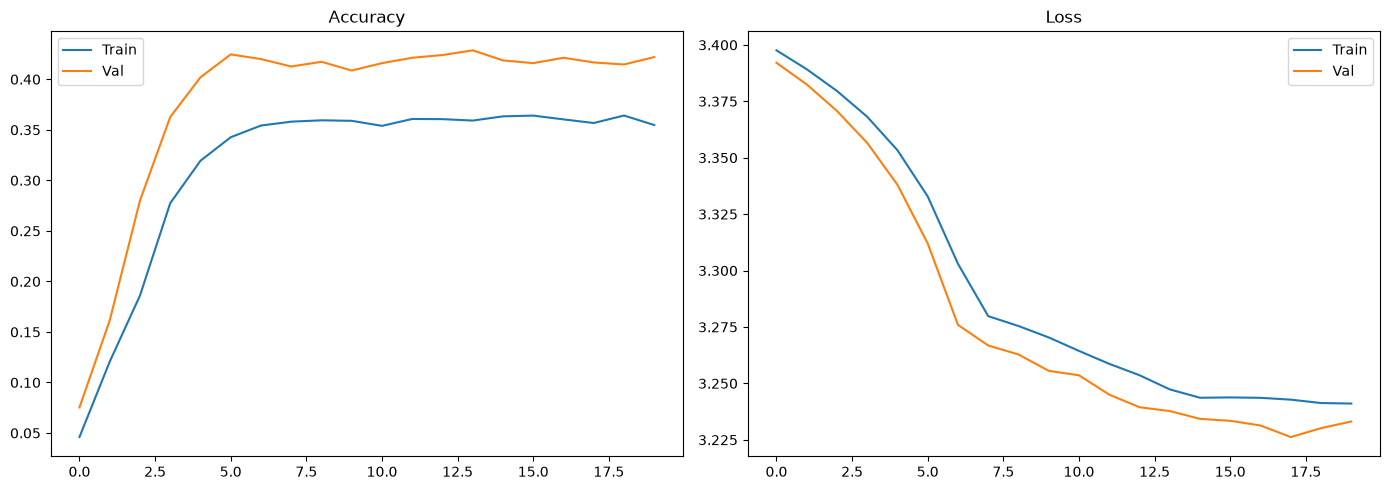

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history['train_acc'], label='Train')
axes[0].plot(history['val_acc'], label='Val')
axes[0].set_title('Accuracy'); axes[0].legend()
axes[1].plot(history['train_loss'], label='Train')
axes[1].plot(history['val_loss'], label='Val')
axes[1].set_title('Loss'); axes[1].legend()
plt.tight_layout(); plt.savefig('results_shufflenet.png', dpi=100); plt.show()

## 8. Evaluasi pada Test Set + Confusion Matrix

In [12]:
def evaluate(model, loader, device):
    model.eval()
    real, pred = [], []
    with torch.no_grad():
        for images, labels in tqdm(loader, desc='eval'):
            images = images.to(device, non_blocking=True)
            outputs = model(images)
            _, p = torch.max(outputs, 1)
            pred.extend(p.cpu().numpy().tolist())
            real.extend(labels.numpy().tolist())
    return real, pred

y_true, y_pred = evaluate(model, dataloaders['test'], device)
acc = np.mean(np.array(y_true) == np.array(y_pred))
print(f'Test accuracy: {acc*100:.2f}%')
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

eval: 100%|██████████| 47/47 [00:01<00:00, 28.36it/s]

Test accuracy: 42.87%
                            precision    recall  f1-score   support

              aerosol_cans       0.68      0.26      0.38        50
        aluminum_food_cans       0.34      0.20      0.25        50
        aluminum_soda_cans       0.58      0.44      0.50        50
           cardboard_boxes       0.47      0.58      0.52        50
       cardboard_packaging       0.44      0.24      0.31        50
                  clothing       0.59      0.40      0.48        50
            coffee_grounds       0.33      0.96      0.49        50
disposable_plastic_cutlery       0.90      0.72      0.80        50
                 eggshells       0.28      0.86      0.42        50
                food_waste       0.20      0.84      0.32        50
    glass_beverage_bottles       0.46      0.52      0.49        50
 glass_cosmetic_containers       0.49      0.38      0.43        50
           glass_food_jars       0.68      0.46      0.55        50
                 magazine

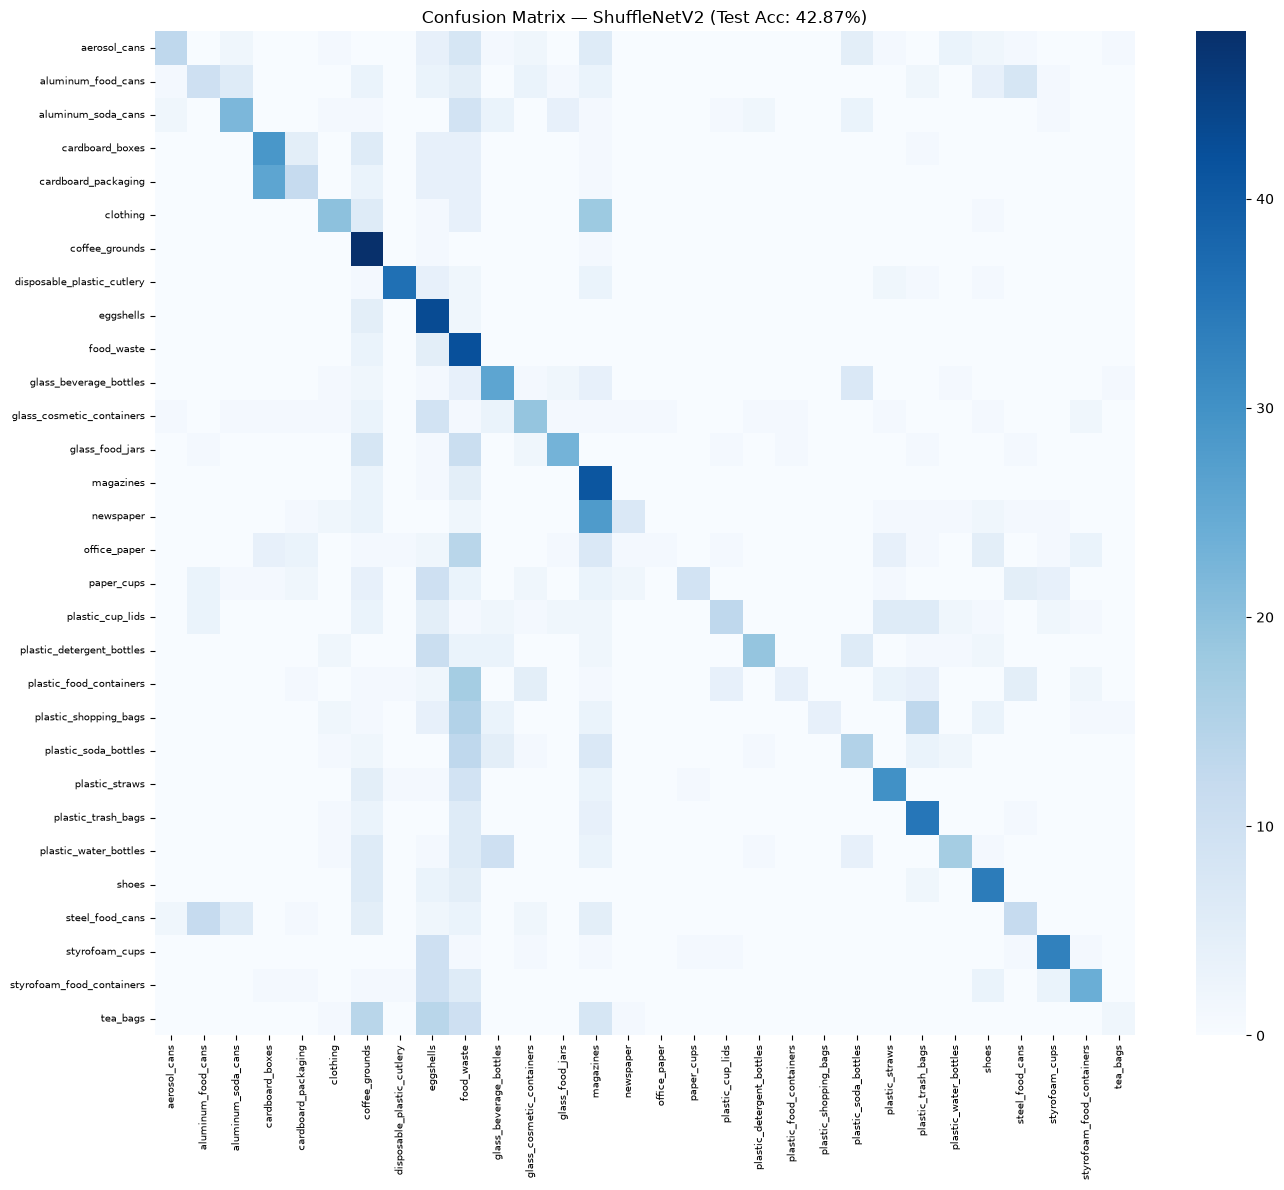

In [13]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix — ShuffleNetV2 (Test Acc: {acc*100:.2f}%)')
plt.xticks(rotation=90, fontsize=7); plt.yticks(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Prediksi Single Image

File: waste_shufflenet_data/split/test/tea_bags/default_Image_79.png
True: tea_bags
Pred: magazines (conf=0.036)


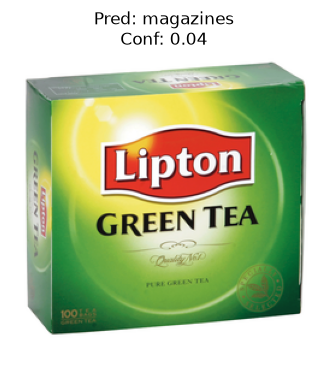

In [20]:
def predict_single(img_path, model, class_names, device=device):
    model.eval()
    tfm = transforms.Compose([
        transforms.Resize([224, 224]),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    img = Image.open(img_path).convert('RGB')
    x = tfm(img).unsqueeze(0).to(device)
    with torch.no_grad():
        out = model(x)
        probs = torch.softmax(out, dim=1)
        conf, idx = torch.max(probs, 1)
    return class_names[idx.item()], conf.item()

test_ds = datasets.ImageFolder(str(SPLIT_DIR / 'test'))
sample_idx = random.randint(0, len(test_ds) - 1)
sample_path, true_idx = test_ds.samples[sample_idx]
pred_class, conf = predict_single(sample_path, model, class_names)
print(f'File: {sample_path}')
print(f'True: {class_names[true_idx]}')
print(f'Pred: {pred_class} (conf={conf:.3f})')
plt.figure(figsize=(4, 4)); plt.imshow(Image.open(sample_path))
plt.title(f'Pred: {pred_class}\nConf: {conf:.2f}'); plt.axis('off'); plt.show()